----
# Laboratorium 5 - Wpływ położenia biegunów na odpowiedź impulsową w układzie RLC II rzędu
----
Materiały dydaktyczne przeznaczone są wyłącznie dla studentów Wydziału Informatyki i Telekomunikacji Politechniki Poznańskiej 

----
# 0. Zagadnienia do opanowania przed zajęciami
----
- odpowiedź impulsowa 

- miejsca zerowe wielomianu

- bieguny transmitancji

- transformacja Laplace'a i odwrotna transformacja Laplace'a (metoda residuów) 

Funkcje z biblioteki *scipy.signal* potrzebne do zrealizowania ćwiczenia:  
`scipy.signal.freqresp`, `scipy.signal.signal.tf2ss`,  `scipy.signal.impulse`

Dokumentacja i opisy poszczególnych funkcji *scipy.signal*:  
https://docs.scipy.org/doc/scipy/reference/signal.html    



## 🧭 Jak czytać ten notatnik
To Twój notatnik – Twój kod został, ale ma **komentarz przy każdej linijce** i kilka poprawek (opisane w „🛠 Poprawki”). Dopisane: zadanie 4, rozbudowane zadanie 2 i 5, sekcje **📘 Teoria**, **🔧 Składnia**, **💡 Wyjaśnienie** / **✅ Wnioski** i **📝 ściąga** na końcu.

### 📘 Teoria

**Odpowiedź impulsowa $h(t)$** – to, co układ „wypluje”, gdy na wejście podamy bardzo krótki, bardzo silny impuls $\delta(t)$ (impuls Diraca). Opisuje układ tak samo kompletnie jak transmitancja, bo
$$H(s)=\mathcal{L}\{h(t)\}\qquad\text{(transmitancja to transformata Laplace'a odpowiedzi impulsowej)}$$

**Bieguny** – miejsca zerowe **mianownika** $A(s)$ transmitancji (tam $H(s)\to\infty$). Liczby zespolone $p=\sigma+j\omega_d$.

**Dlaczego bieguny decydują o odpowiedzi?** Z odwrotnej transformaty Laplace'a (metoda residuów) każdy biegun $p$ daje w $h(t)$ składnik
$$e^{p t}=e^{\sigma t}\,e^{j\omega_d t}$$
- $\sigma=\mathrm{Re}\,p$ → **zanikanie** ($\sigma<0$), **stała amplituda** ($\sigma=0$) albo **narastanie** ($\sigma>0$),
- $\omega_d=\mathrm{Im}\,p$ → **drgania** z pulsacją $\omega_d$ (jeśli $\omega_d=0$ – brak drgań).

**Stabilność BIBO** (Bounded Input → Bounded Output: ograniczone wejście daje ograniczone wyjście) ⇔ $\int_0^\infty|h(t)|\,dt<\infty$ ⇔ **wszystkie bieguny w lewej półpłaszczyźnie** ($\mathrm{Re}\,p<0$).

In [1]:
%matplotlib inline
import numpy as np                 # obliczenia numeryczne
import matplotlib.pyplot as plt    # wykresy
import scipy.signal                # odpowiedź impulsowa (impulse, tf2ss)
import sympy                       # transmitancja symbolicznie
poles_figsize  =(8, 8)             # kwadratowe okno do wykresów biegunów
default_figsize=(14, 8)            # okno do pozostałych wykresów

----
# 1. Wyznaczanie transmitancji operatorowej układu RLC oraz wyznaczanie biegunów transmitancji
----
## 1.1 Zadanie: Wyznacz transmitancję operatorową dla następującego układu I rzędu:


Dla poniższej transmitancji układu RC I rzędu zastosowano bibliotekę Sympy wyznaczającą symbolicznie transmitancję operatorową. 



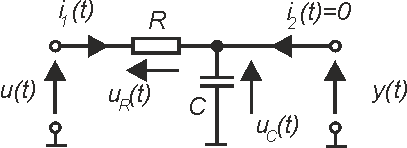
                         
                         
                         

### 📘 Teoria

**Impedancje w dziedzinie $s$** (po transformacji Laplace'a elementy RLC zachowują się jak „opory”):
$$Z_R=R,\qquad Z_L=sL,\qquad Z_C=\frac{1}{sC}$$

**Dzielnik napięcia:** wyjście jest zbierane z kondensatora, który jest szeregowo z rezystorem:
$$H_1(s)=\frac{Y(s)}{U(s)}=\frac{Z_C}{Z_R+Z_C}=\frac{\frac{1}{sC}}{R+\frac{1}{sC}}\ \Big|\cdot sC\ =\frac{1}{RCs+1}$$

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `sympy.Symbol('s', ...)` | zmienne symboliczne `s`, `R`, `C` |
| `(1/(s*C)) / (R+(1/(s*C)))` | wzór z dzielnika napięcia wpisany wprost |
| `sympy.simplify(...)` | upraszcza ułamek piętrowy do $\frac{1}{CRs+1}$ |
| `display(...)` | ładne wyświetlenie |

Uwaga: w kodzie prowadzącego jest `real = 'False'` w cudzysłowie – to **tekst**, a niepusty tekst Python traktuje jak `True`. Na wynik transmitancji to nie wpływa, ale poprawnie byłoby bez cudzysłowów (`real=False`).

In [2]:
#declare symbolic variable s (complex), R,L,C
s = sympy.Symbol('s', real = 'False', nonzero = 'True')    # zmienna Laplace'a s
R = sympy.Symbol('R', real = 'True' , nonzero = 'True')    # rezystancja
C = sympy.Symbol('C', real = 'True' , nonzero = 'True')    # pojemność

H1 = (1/(s*C)) / (R+(1/(s*C))) #dzielnik napięcia: Z_C / (Z_R + Z_C)
display(sympy.simplify(H1))                                # → 1 / (CRs + 1)

1/(C*R*s + 1)

----
## 1.2 Dla wyznaczonego mianownika transmitancji wyznacz bieguny

W tym celu zdefiniuj wektor złożony ze współczynników przy każdej zmiennej s do stopnia danego wielomianu. Wykorzystaj funkcję `np.poly1d` oraz `np.roots`.
Uwaga, jeśli dla układu definiujemy transmitancję jako współczynniki licznika i mianownika (num, den), to współczynniki powinny być podane w kolejności malejącego wykładnika (np. s^2 + 3s + 5 byłyby reprezentowane jako [1, 3, 5]). W miejsce R i C podstaw wartości jednostkowe. 
Przedstaw położenie biegunów na płąszczyźnie zespolonej krzyżykami.


### 📘 Teoria

Mianownik $A(s)=RCs+1$. Przy $R=C=1$: $A(s)=s+1$ → współczynniki `[1, 1]`. Biegun: $s+1=0\Rightarrow s=-1$.

Odpowiedź impulsowa: $H_1(s)=\frac{1}{s+1}\ \Rightarrow\ h(t)=e^{-t}$ – zanika, bo biegun jest ujemny.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.poly1d([1, 1])` | wielomian $s+1$ (współczynniki od najwyższej potęgi) |
| `np.roots(A1)` | **miejsca zerowe** wielomianu → bieguny (wektor, może zawierać liczby zespolone) |
| `poles1.real`, `poles1.imag` | części rzeczywiste i urojone biegunów → współrzędne na płaszczyźnie zespolonej |
| `plt.plot(x, y, 'rx')` | `'r'` czerwony, `'x'` krzyżyk – tak oznacza się bieguny |
| `plt.xlim([a, b])`, `plt.ylim([a, b])` | zakres osi |
| `np.all(warunek)` | `True`, gdy warunek jest prawdziwy dla **wszystkich** elementów |

### 🛠 Poprawka
W tytule było „bieguny **transmutacji**” → „bieguny **transmitancji**”.

bieguny = [-1.]


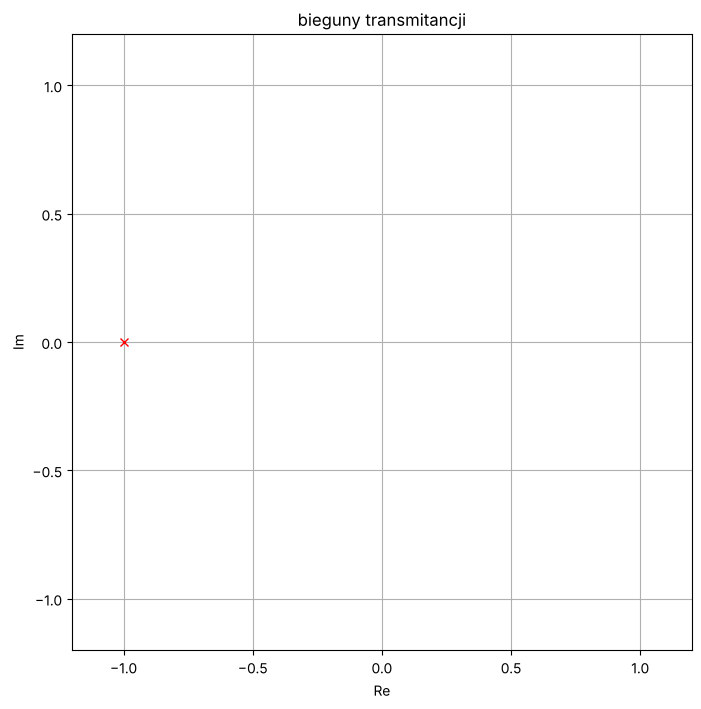

In [3]:
B1 = np.poly1d([ 1])               # licznik H1:   1
A1 = np.poly1d([1, 1])             # mianownik H1: s + 1   (RC·s + 1 dla R = C = 1)
poles1 = np.roots(A1)              # bieguny = miejsca zerowe mianownika
print("bieguny = " + str(poles1))

plt.figure(figsize=poles_figsize)  # kwadratowe okno
plt.plot(poles1.real,poles1.imag,'rx')     # biegun jako czerwony krzyżyk w punkcie (Re, Im)
plt.title("bieguny transmitancji")         # (POPRAWIONE: było „transmutacji”)
plt.xlabel("Re")                   # oś rzeczywista
plt.ylabel("Im")                   # oś urojona
plt.xlim([-1.2,1.2])               # zakres osi
plt.ylim([-1.2,1.2])
plt.grid()
plt.show()

In [4]:
# sprawdzenie stabilności: wszystkie bieguny muszą mieć część rzeczywistą < 0
if np.all(poles1.real < 0):
    print('Wszystkie bieguny w lewej półpłaszczyźnie → układ RC jest stabilny (BIBO)')
else:
    print('Układ nie jest stabilny')

Wszystkie bieguny w lewej półpłaszczyźnie → układ RC jest stabilny (BIBO)


----
## 1.3 Dla układu II rzędu przedstawionego poniżej wyznacz transmitancję operatorową i wyznacz położenie biegunów. 
Dokonaj uproszczenia z wykorzystaniem funkcji `sympy.cancel`. Zwróć uwagę na różnicę między zastosowaniem funkcji `sympy.symplify` a `sympy.cancel` 

<br>
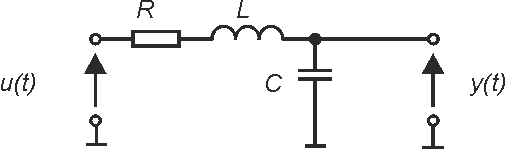



### 📘 Teoria

Na schemacie $R$, $L$ i $C$ są połączone **szeregowo**, wyjście zbierane z kondensatora. To znowu dzielnik napięcia, tylko na „górze” jest $R+sL$:
$$H_2(s)=\frac{\frac{1}{sC}}{R+sL+\frac{1}{sC}}\ \Big|\cdot sC\ =\frac{1}{LCs^2+RCs+1}$$

Mianownik jest **drugiego stopnia** → **dwa bieguny**:
$$s_{1,2}=\frac{-RC\pm\sqrt{(RC)^2-4LC}}{2LC}$$
Przy $R=L=C=1$: $s^2+s+1=0$, $\Delta=1-4=-3<0$ → bieguny **zespolone sprzężone** $s_{1,2}=-\frac12\pm j\frac{\sqrt3}{2}\approx-0{,}5\pm0{,}866j$.

### 🔧 Składnia – użyte funkcje

| Funkcja | Co robi | Wynik dla $H_2$ |
|---|---|---|
| `sympy.simplify(H2)` | szuka **najkrótszej** postaci wg własnych kryteriów; nie gwarantuje, jak wynik będzie wyglądał | $\frac{1}{Cs(Ls+R)+1}$ – mianownik nie rozpisany |
| `sympy.cancel(H2)` | sprowadza do postaci **$\frac{\text{wielomian}}{\text{wielomian}}$**, z wielomianami rozpisanymi wg potęg i skróconymi wspólnymi czynnikami | $\frac{1}{CLs^2+CRs+1}$ |

**Wniosek:** do odczytania współczynników dla `np.poly1d` lepszy jest `cancel` – od razu widać `[L*C, R*C, 1]`.

In [5]:
#declare symbolic variable s (complex), R,L,C
s = sympy.Symbol('s', real = 'False', nonzero = 'True')    # zmienna Laplace'a
R = sympy.Symbol('R', real = 'True' , nonzero = 'True')    # rezystancja
C = sympy.Symbol('C', real = 'True' , nonzero = 'True')    # pojemność
L = sympy.Symbol('L', real = 'True' , nonzero = 'True')    # indukcyjność

H2 = (1/(s*C)) / (R + s*L + 1/(s*C))   # dzielnik napięcia: Z_C / (Z_R + Z_L + Z_C)
display(sympy.simplify(H2))            # postać „najkrótsza” → 1/(Cs(Ls+R)+1)
display(sympy.cancel(H2))              # postać wielomian/wielomian → 1/(CLs²+CRs+1)

1/(C*s*(L*s + R) + 1)

1/(C*L*s**2 + C*R*s + 1)

### 🛠 Poprawka
W mianowniku było `[1*C, R*C, 1]` – pierwszy współczynnik to $L\cdot C$, nie $1\cdot C$. Przy $L=1$ wynik ten sam, ale dla innego $L$ byłby zły. Poprawione na `[L*C, R*C, 1]`.

In [6]:
C=1                                # wartości liczbowe (nadpisują symbole sympy!)
L=1
R=1

B2 = np.poly1d([1])                # licznik H2: 1
A2 = np.poly1d([L*C,R*C,1])        # mianownik H2: LC·s² + RC·s + 1   (POPRAWIONE: było 1*C)
poles2 = np.roots(A2)              # dwa bieguny
display("bieguny = " + str(poles2))

'bieguny = [-0.5+0.8660254j -0.5-0.8660254j]'

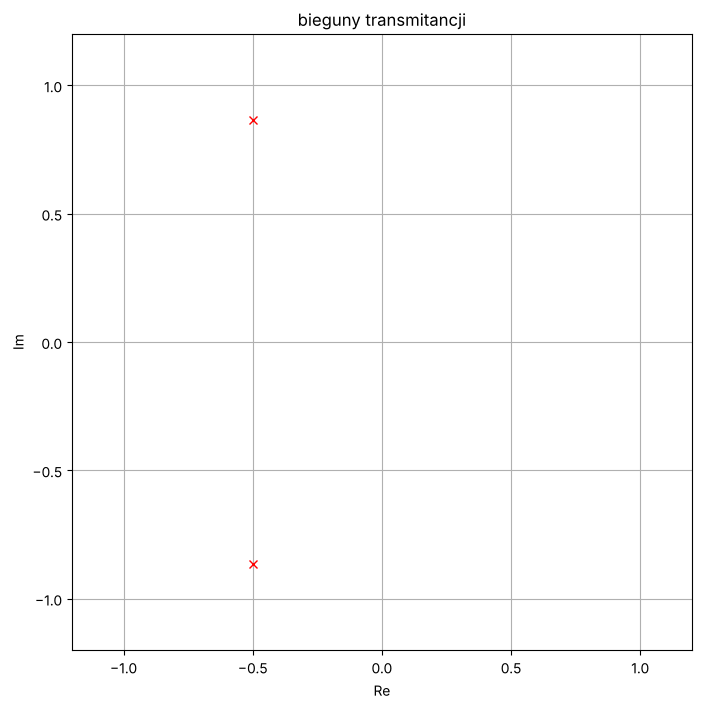

In [7]:
plt.figure(figsize=poles_figsize)
plt.plot(poles2.real,poles2.imag,'rx')     # dwa krzyżyki: -0.5 ± 0.866j
plt.title("bieguny transmitancji")         # (POPRAWIONE: było „transmutacji”)
plt.xlabel("Re")
plt.ylabel("Im")
plt.xlim([-1.2,1.2])
plt.ylim([-1.2,1.2])
plt.grid()
plt.show()

### 💡 Wyjaśnienie wyniku

Dwa bieguny symetryczne względem osi rzeczywistej (sprzężone), w lewej półpłaszczyźnie. Część urojona ≠ 0 → odpowiedź będzie **drgać**, część rzeczywista $-0{,}5<0$ → drgania będą **gasnąć**.

---- 
## 2. Układ II rzędu - odpowiedź impulsowa i charakterystykę amplitudowo-fazowa
---- 
### Dla układu II rzędu przedstawionego na samym początku wyznacz odpowiedź impulsową oraz wykreśl charakterystykę amplitudowo-fazową tzw. wykres Nyguista.

Sprawdź na przykładzie odpowiedzi o charakterze drgań sinusoidalnych gasnących, jaki wpływ na częstotliwość charakterystyczną układu  $ \omega_0 = {1 \over \sqrt {LC} }  $ ma zmiana wartości pojemności? $ \xi $ ustaw na wartość bliską 0, ale nie zerową! 

Dla przypomnienia, transmitancja operatorowa układu II rzędu wyrażona za pomocą zmiennych opisujących zachowanie się odpowiedzi impulsowej

$$ H(s) = {\omega_0^2 \over s^2+2 \xi \omega_0 s + \omega_0^2}   $$

Na podstawie charakterystyki amplitudowo-fazowej określ charakter częstotliwościowy filtru (dolno-, górno- , pasmowo-przepustowy)?

### 📘 Teoria

**Postać kanoniczna** układu II rzędu – dzielimy licznik i mianownik $H_2$ przez $LC$:
$$H(s)=\frac{\frac{1}{LC}}{s^2+\frac{R}{L}s+\frac{1}{LC}}=\frac{\omega_0^2}{s^2+2\xi\omega_0 s+\omega_0^2}$$
Porównując:
$$\omega_0=\frac{1}{\sqrt{LC}}\ \text{(pulsacja drgań własnych)},\qquad 2\xi\omega_0=\frac RL\ \Rightarrow\ \xi=\frac R2\sqrt{\frac CL}\ \text{(współczynnik tłumienia)}$$

Dla $0<\xi<1$ odpowiedź impulsowa to drgania gasnące:
$$h(t)=\frac{\omega_0}{\sqrt{1-\xi^2}}\,e^{-\xi\omega_0 t}\sin\!\left(\omega_0\sqrt{1-\xi^2}\,t\right)$$
Przy małym $\xi$ drgają z pulsacją $\approx\omega_0$, czyli z okresem $T\approx\frac{2\pi}{\omega_0}=2\pi\sqrt{LC}$.

**Wpływ pojemności:** $\omega_0=\frac{1}{\sqrt{LC}}$ → **większe C = mniejsze $\omega_0$** = wolniejsze drgania (dłuższy okres).

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `scipy.signal.tf2ss(B, A)` | zamienia transmitancję (licznik, mianownik) na **model w przestrzeni stanów** – postać, którą przyjmuje `impulse` |
| `scipy.signal.impulse(układ, T=czas)` | liczy odpowiedź impulsową w chwilach `czas`; **zwraca parę** `(czas, odpowiedź)` – dlatego `[1]` wybiera samą odpowiedź |
| `np.sqrt(x)` | pierwiastek (numerycznie) |
| `B(s) / A(s)` | wartość transmitancji dla wektora `s = jω` |
| `for C in [0.2, 1, 5]:` | pętla po kilku wartościach pojemności – każda daje jedną krzywą |
| `label=f'C = {C}'` + `plt.legend()` | opis krzywej w legendzie |

In [8]:
def calculateImpulseResponseFromNumDen(B, A, TimeDomain):
    step = scipy.signal.impulse(scipy.signal.tf2ss(B, A), T=TimeDomain)[1]   # [1] → sama odpowiedź (bez wektora czasu)
    return step

### 🛠 Poprawka
Przerobione z `fig, ax` na `plt` i dodana pętla po kilku wartościach $C$ – dzięki temu od razu widać odpowiedź na pytanie z zadania.

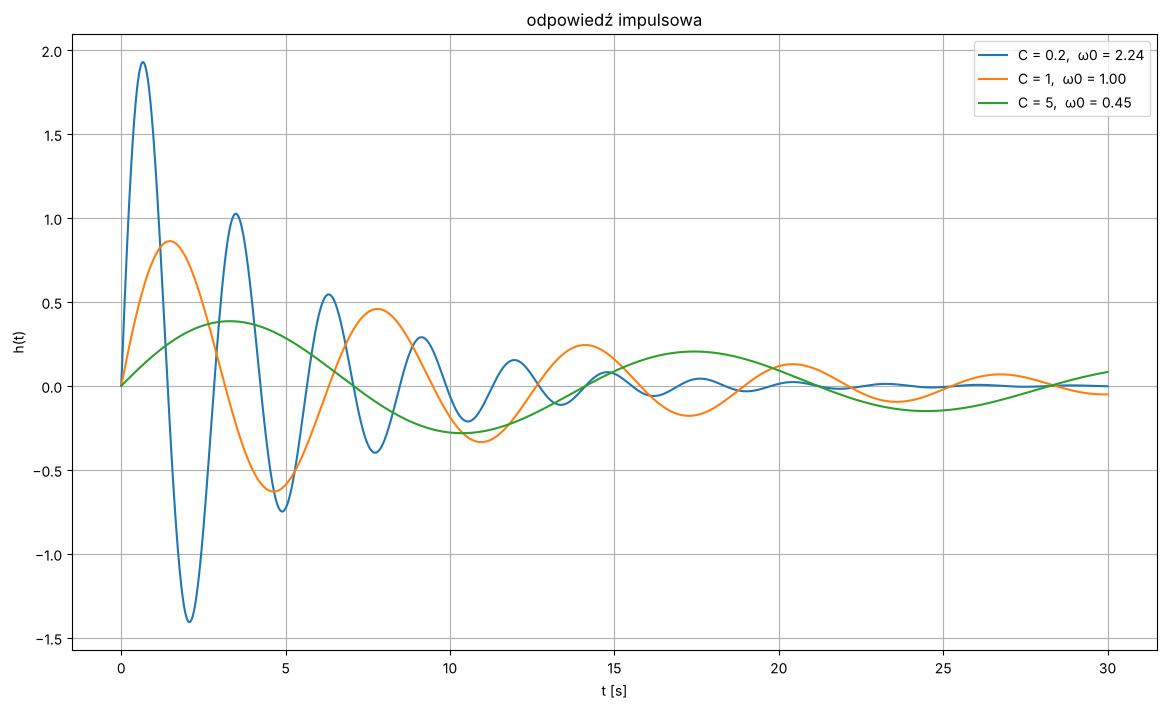

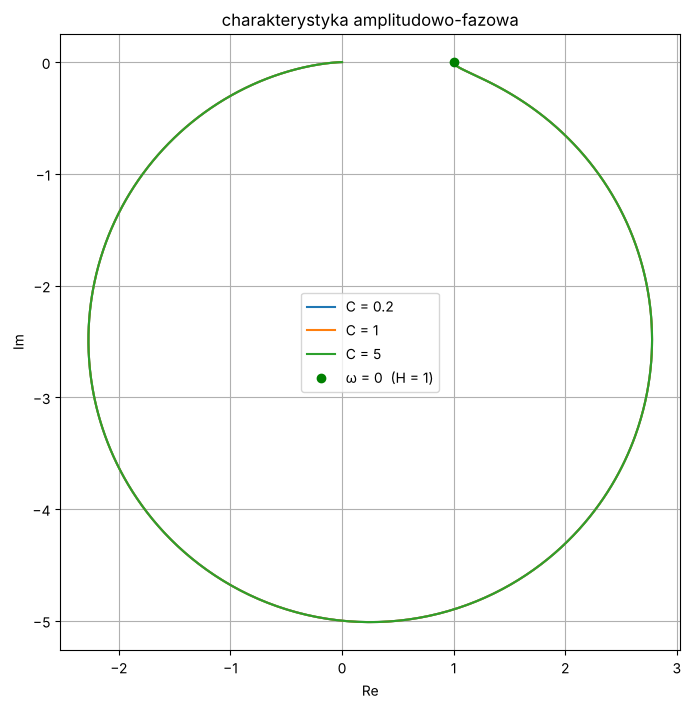

In [9]:
L=1                                # indukcyjność
ξ=0.1                              # współczynnik tłumienia – bliski 0, ale nie 0 (drgania gasnące)
time = np.linspace(0, 30, 2000)    # oś czasu 0…30 s
w = np.logspace(-2, 2, 10000)      # pulsacje do wykresu Nyquista
s = w * 1j                         # s = jω

#odpowiedź impulsowa
plt.figure(figsize=default_figsize)
for C in [0.2, 1, 5]:                          # trzy różne pojemności
    ω0 = (1/np.sqrt(L*C))                      # pulsacja drgań własnych ω0 = 1/√(LC)
    B  = np.poly1d([           ω0**2])         # licznik:   ω0²
    A  = np.poly1d([1, 2*ξ*ω0, ω0**2])         # mianownik: s² + 2ξω0·s + ω0²
    impulse = calculateImpulseResponseFromNumDen(B, A, time)       # h(t)
    plt.plot(time, impulse, label=f'C = {C},  ω0 = {ω0:.2f}')      # wykres z opisem
plt.title("odpowiedź impulsowa")
plt.xlabel("t [s]")
plt.ylabel("h(t)")
plt.legend()
plt.grid()
plt.show()

#charakterystyka amplitudowo-fazowa
plt.figure(figsize=poles_figsize)
for C in [0.2, 1, 5]:
    ω0 = (1/np.sqrt(L*C))
    B  = np.poly1d([           ω0**2])
    A  = np.poly1d([1, 2*ξ*ω0, ω0**2])
    H = B(s) / A(s)                            # H(jω)
    plt.plot(H.real, H.imag, label=f'C = {C}') # krzywa Nyquista
plt.plot(1, 0, 'go', label='ω = 0  (H = 1)')   # punkt startowy wszystkich krzywych
plt.title("charakterystyka amplitudowo-fazowa")
plt.xlabel("Re")
plt.ylabel("Im")
plt.axis('equal')                              # równa skala osi
plt.legend()
plt.grid()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

**Wpływ pojemności:**
- $C=0{,}2$ → $\omega_0\approx2{,}24$, okres $\approx2{,}8$ s – szybkie drgania,
- $C=1$ → $\omega_0=1$, okres $\approx6{,}3$ s,
- $C=5$ → $\omega_0\approx0{,}45$, okres $\approx14$ s – wolne drgania.

**Większa pojemność → mniejsza częstotliwość charakterystyczna** (bo $\omega_0=\frac{1}{\sqrt{LC}}$). Mniejsze $C$ daje też **wyższą** pierwszą „górkę” (amplituda odpowiedzi impulsowej rośnie z $\omega_0$).

**Wykres Nyquista:** kształt krzywej **nie zależy od C** (wszystkie się pokrywają) – zależy tylko od $\xi$. Zmienia się tylko, przy jakim $\omega$ jesteśmy w danym punkcie.

**Charakter filtru – dolnoprzepustowy:**
- $\omega\to0$: $H=\frac{\omega_0^2}{\omega_0^2}=1$ → niskie częstotliwości przechodzą bez zmian (punkt $(1,0)$),
- $\omega\to\infty$: $H\approx\frac{\omega_0^2}{-\omega^2}\to0$ → wysokie są wycinane (krzywa wraca do $(0,0)$),
- duża pętla przy małym $\xi$ to **rezonans** w okolicy $\omega_0$ (max $|H|\approx\frac{1}{2\xi}=5$).

---- 
## 3. Analiza zmiany charakteru odpowiedzi impulsowej oraz zmiany położenia biegunów w funkcji zmiany wartości współczynnika tłumienia 
---- 

Na jednym wykresie zebrać odpowiedzi impulsowe dla przypadków: 

$\begin{align}
& \text {a)  }  0 < \xi < 1 \text { - drgan sinusoidalnych gasnacych} \\
& \text {b)  }  \xi = 0 \text { - drgan sinusoidalnych (generator)} \\
& \text {c)  }  \xi = 1 \text { - przypadku aperiodyczo-krytycznego} \\
& \text {d)  }  \xi > 1 \text { - przypadku przetlumionego}
 \end{align}$

Do odpowiedniej wartości $ \xi $ dopasuj wartości elementów R, L i C. Zalężność na $ \xi $ jest następująca:

$$ 2 \xi = R \sqrt {C \over L} $$

Na drugim wykresie zbierz położenia biegunów dla tych samych przypadków a)-d). Na podstawie otrzymanych wyników wyciągnąć wnioski na temat wpływu położenia biegunów transmitancji układu na jego odpowiedź impulsową? Dla każdego z przypadków odpowiedz czy odpowiedź jest stabilna w sensie BIBO?


### 📘 Teoria

Bieguny w zależności od $\xi$ (z postaci kanonicznej):
$$s_{1,2}=\omega_0\left(-\xi\pm\sqrt{\xi^2-1}\right)$$

| przypadek | $\xi$ | bieguny | $h(t)$ |
|---|---|---|---|
| a) gasnące | $0<\xi<1$ | zespolone, $\mathrm{Re}<0$ | $e^{-\xi\omega_0t}\sin(\dots)$ – drgania gasnące |
| b) generator | $\xi=0$ | **czysto urojone** $\pm j\omega_0$ | $\sin(\omega_0t)$ – drgania niegasnące |
| c) krytyczny | $\xi=1$ | **podwójny** rzeczywisty $-\omega_0$ | $t\,e^{-\omega_0t}$ – najszybszy powrót bez drgań |
| d) przetłumiony | $\xi>1$ | dwa różne rzeczywiste ujemne | suma dwóch eksponent – powolny zanik |

**Dobór R, L, C** (z $2\xi=R\sqrt{C/L}$; dla $L=C=1$: $\xi=\frac R2$):

| | R | L | C | $\xi$ | bieguny |
|---|---|---|---|---|---|
| a) | 0,5 | 1 | 1 | 0,25 | $-0{,}25\pm0{,}97j$ |
| b) | 0 | 1 | 1 | 0 | $\pm j$ |
| c) | 2 | 1 | 1 | 1 | $-1$ (podwójny) |
| d) | 5 | 4 | 1 | 1,25 | $-1;\ -0{,}25$ |

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `Systems = {"nazwa": {"R": .., "L": .., "C": ..}, ...}` | **słownik słowników** – każdy przypadek ma nazwę i swoje parametry |
| `for Name, Params in Systems.items():` | pętla po przypadkach: `Name` = klucz (napis), `Params` = wewnętrzny słownik |
| `R,L,C = Params["R"],Params["L"],Params["C"]` | odczyt trzech wartości naraz |
| `plt.plot(..., 'x', markersize=12)` | krzyżyki większe niż domyślne |

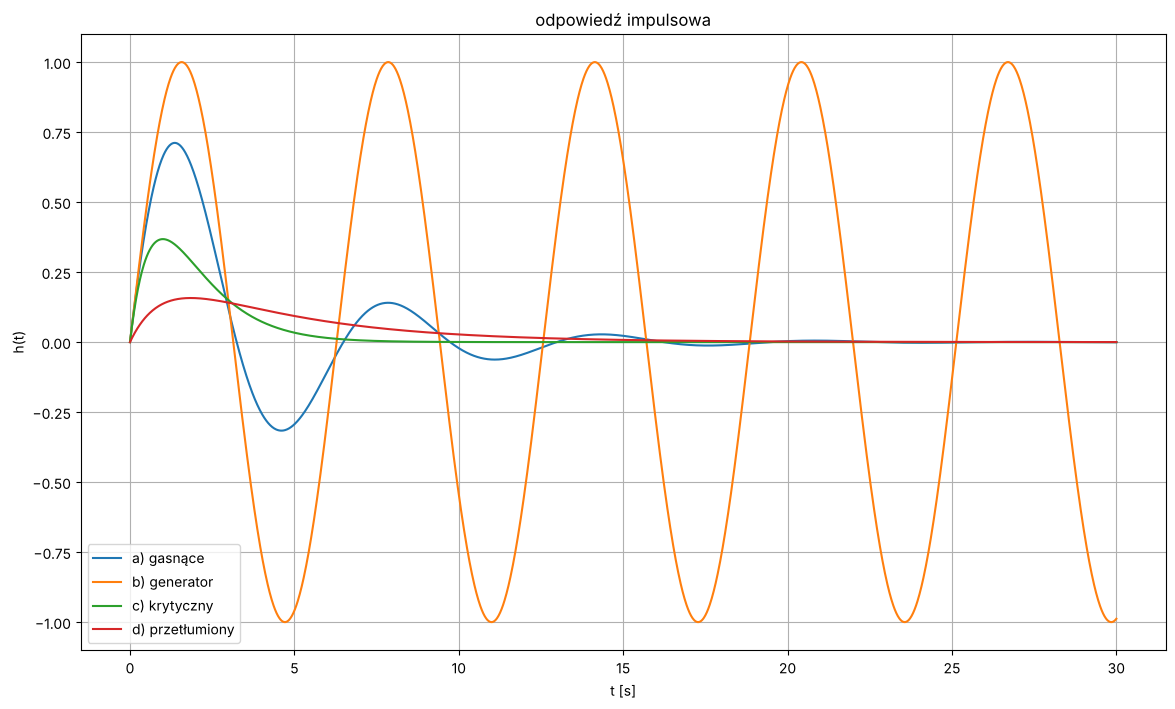

a) gasnące         bieguny = [-0.25+0.968j -0.25-0.968j]
b) generator       bieguny = [-0.+1.j  0.-1.j]
c) krytyczny       bieguny = [-1. -1.]
d) przetłumiony    bieguny = [-1.   -0.25]


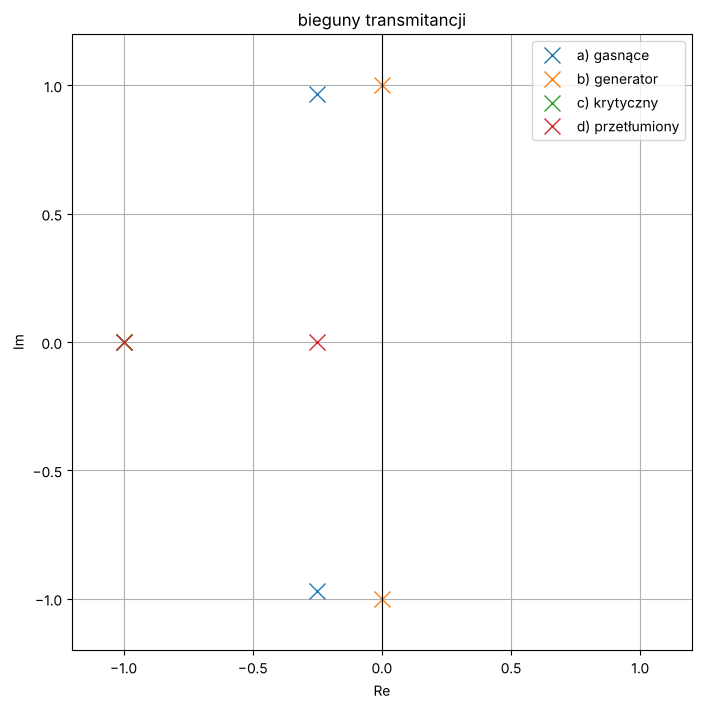

In [10]:
time = np.linspace(0, 30, 2000)    # oś czasu 0…30 s

Systems = {                                                 # przypadki a)–d): nazwa → parametry R, L, C
  "a) gasnące" : {"R" : 0.5, "L" : 1, "C" : 1},             # ξ = 0.25
  "b) generator" : {"R" : 0, "L" : 1, "C" : 1},             # ξ = 0
  "c) krytyczny" : {"R" : 2, "L" : 1, "C" : 1},             # ξ = 1
  "d) przetłumiony" : {"R" : 5, "L" : 4, "C" : 1},          # ξ = 1.25
}

plt.figure(figsize=default_figsize)                          # wykres 1: odpowiedzi impulsowe
for Name, Params in Systems.items():
  R,L,C = Params["R"],Params["L"],Params["C"]                # parametry tego przypadku
  B = np.poly1d([1])                                         # licznik: 1
  A = np.poly1d([L*C,R*C,1])                                 # mianownik: LC·s² + RC·s + 1
  impulse = calculateImpulseResponseFromNumDen(B,A,time)     # h(t)
  plt.plot(time,impulse,label=Name)                          # krzywa z opisem
plt.title("odpowiedź impulsowa")
plt.xlabel("t [s]")
plt.ylabel("h(t)")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=poles_figsize)                            # wykres 2: bieguny
for Name, Params in Systems.items():
  R,L,C = Params["R"],Params["L"],Params["C"]
  A = np.poly1d([L*C,R*C,1])                                 # mianownik
  poles = np.roots(A)                                        # bieguny
  print(f'{Name:18s} bieguny = {np.round(poles, 3)}')        # wypisanie (zaokrąglone do 3 miejsc)
  plt.plot(poles.real,poles.imag,'x',markersize=12,label=Name)   # krzyżyki w kolorze przypadku
plt.axvline(0, color='k', linewidth=0.8)                     # oś urojona – granica stabilności
plt.title("bieguny transmitancji")
plt.xlabel("Re")
plt.ylabel("Im")
plt.xlim([-1.2,1.2])
plt.ylim([-1.2,1.2])
plt.legend()
plt.grid()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

**Wpływ położenia biegunów na odpowiedź impulsową:**
- **Część urojona** bieguna ≠ 0 → odpowiedź **drga** (a, b); im dalej od osi rzeczywistej, tym szybsze drgania. Bieguny na osi rzeczywistej (c, d) → **brak drgań**.
- **Część rzeczywista** bieguna decyduje o obwiedni $e^{\sigma t}$: im **bardziej w lewo**, tym **szybciej** odpowiedź gaśnie. Biegun blisko zera (d: $-0{,}25$) → bardzo powolny zanik.
- Biegun **na osi urojonej** (b) → amplituda stała, nic nie gaśnie.

**Stabilność BIBO:**
| przypadek | stabilny? | dlaczego |
|---|---|---|
| a) gasnące | ✅ tak | $\mathrm{Re}=-0{,}25<0$, $h(t)\to0$, $\int|h|<\infty$ |
| b) generator | ❌ **nie** (granica stabilności) | bieguny na osi urojonej, $h(t)=\sin t$ nie zanika → $\int_0^\infty|\sin t|\,dt=\infty$. Np. wejście $\sin t$ (ograniczone!) daje rezonans i wyjście rosnące jak $t$ |
| c) krytyczny | ✅ tak | podwójny biegun $-1$ |
| d) przetłumiony | ✅ tak | oba bieguny ujemne |

---- 
## 4. Analiza przypadku nierzeczywistego
---- 

Sprawdzić jak będzie wyglądała odpowiedź impulsowa dla ujemnej wartości rezystancji np. R=-1. Wartości L i C przyjąć jednostkowe. Czy odpowiedź impulsowa jest sumowalna? Czy układ jest stabilny BIBO? Wyjaśnić czym charakteryzuje się brak możliwości posumowania odpowiedzi impulsowej.

### 📘 Teoria

Dla $R=-1$, $L=C=1$: $A(s)=s^2-s+1$, bieguny $s=\frac12\pm j\frac{\sqrt3}{2}\approx0{,}5\pm0{,}866j$ – **w prawej półpłaszczyźnie**.

Odpowiedź impulsowa:
$$h(t)=\frac{2}{\sqrt3}\,e^{+0{,}5t}\sin\!\left(\frac{\sqrt3}{2}t\right)$$
Obwiednia $e^{+0{,}5t}$ **rośnie** wykładniczo.

Fizycznie: rezystor zamienia energię na ciepło (tłumi). **Ujemna** rezystancja energię **dostarcza** – drgania się rozkręcają. Zwykły rezystor tak nie działa (stąd „przypadek nierzeczywisty”), ale podobnie zachowują się układy z aktywnym wzmacniaczem w pętli dodatniego sprzężenia zwrotnego.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.cumsum(x) * dt` | **suma narastająca** – przybliżenie całki $\int_0^t|h|\,d\tau$ (do sprawdzenia sumowalności) |
| `time[1] - time[0]` | krok czasu `dt` |
| `plt.semilogy(t, y)` | oś y logarytmiczna – wykładnicze narastanie widać jako prostą |
| `plt.axvline(0)` | pionowa linia x = 0 (oś urojona, granica stabilności) |

bieguny = [0.5+0.866j 0.5-0.866j]
h(30) = 2830949.235901537
∫|h| od 0 do 30 = 4061903.4883148842


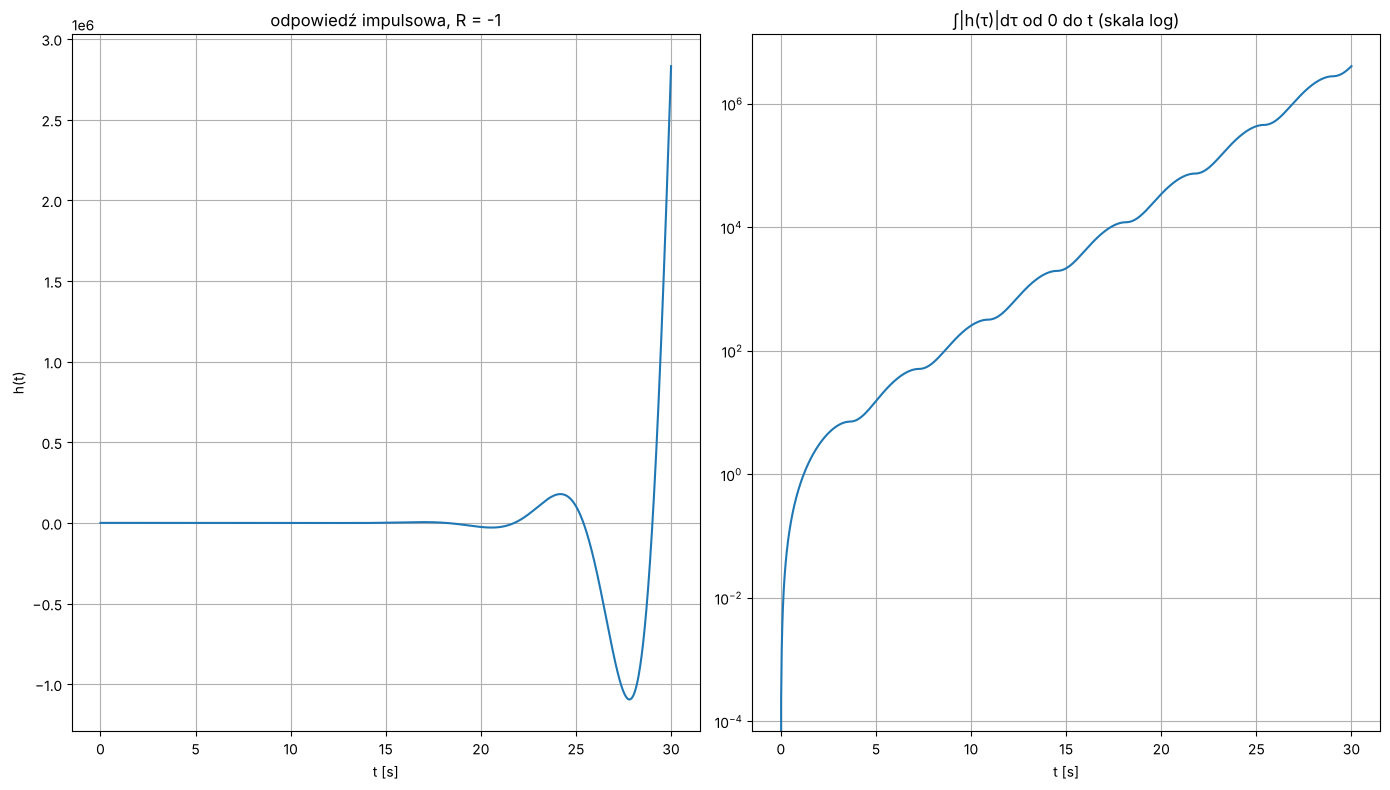

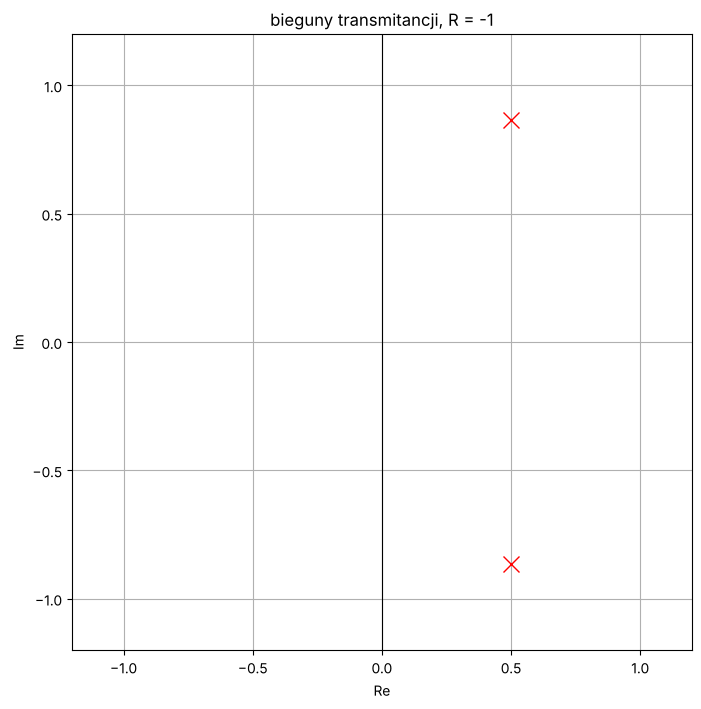

In [11]:
R, L, C = -1, 1, 1                                  # ujemna rezystancja

B = np.poly1d([1])                                  # licznik: 1
A = np.poly1d([L*C, R*C, 1])                        # mianownik: s² - s + 1
poles = np.roots(A)                                 # bieguny
print('bieguny =', np.round(poles, 3))              # 0.5 ± 0.866j

time = np.linspace(0, 30, 2000)                     # oś czasu
impulse = calculateImpulseResponseFromNumDen(B, A, time)   # h(t)
dt = time[1] - time[0]                              # krok czasu
calka = np.cumsum(np.abs(impulse)) * dt             # ∫|h(τ)|dτ od 0 do t (suma prostokątów)
print('h(30) =', impulse[-1])                       # wartość na końcu
print('∫|h| od 0 do 30 =', calka[-1])

plt.figure(figsize=default_figsize)
plt.subplot(1, 2, 1)
plt.plot(time, impulse)                             # odpowiedź impulsowa
plt.title('odpowiedź impulsowa, R = -1')
plt.xlabel('t [s]')
plt.ylabel('h(t)')
plt.grid()
plt.subplot(1, 2, 2)
plt.semilogy(time, calka)                           # całka |h| w skali log
plt.title('∫|h(τ)|dτ od 0 do t (skala log)')
plt.xlabel('t [s]')
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=poles_figsize)
plt.plot(poles.real, poles.imag, 'rx', markersize=12)   # bieguny
plt.axvline(0, color='k', linewidth=0.8)            # granica stabilności
plt.title('bieguny transmitancji, R = -1')
plt.xlabel('Re')
plt.ylabel('Im')
plt.xlim([-1.2, 1.2])
plt.ylim([-1.2, 1.2])
plt.grid()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

- **Bieguny** $0{,}5\pm0{,}866j$ leżą w **prawej** półpłaszczyźnie.
- **Odpowiedź impulsowa** to drgania o **rosnącej** amplitudzie (obwiednia $e^{0{,}5t}$): przy $t=30$ s rzędu $10^6$.
- **Czy jest sumowalna?** **Nie.** $\int_0^\infty|h(t)|\,dt=\infty$ – na wykresie w skali log całka rośnie jak prosta, czyli wykładniczo, bez końca.
- **Czy układ jest stabilny BIBO?** **Nie.** Warunek konieczny i wystarczający stabilności BIBO to właśnie bezwzględna sumowalność $h(t)$.
- **Czym charakteryzuje się brak sumowalności?** Istnieje **ograniczone** wejście, dla którego wyjście rośnie **bez ograniczeń**. Tu wystarczy sam impuls (albo nawet minimalny szum) – układ „rozkręca się” sam z siebie. W praktyce taki układ się nasyca albo ulega uszkodzeniu.

---- 
## 5. Obejrzeć trójwymiarowy wykres transmitancji w funkcji zmiennej "s" dla przypadku drgań sinusoidalnych gasnących
---- 

Zmieniając wartość rezystora R, sprawdzić zmianę położenia biegunów oraz kształ transmitancji.



### 📘 Teoria

Transmitancja $H(s)$ to funkcja **zmiennej zespolonej** – dla każdego punktu płaszczyzny $s=\sigma+j\omega$ ma jakąś wartość. Rysujemy $\log|H(s)|$ jako powierzchnię nad tą płaszczyzną:
- **bieguny** → $|H|\to\infty$ → wysokie „kominy”,
- przekrój powierzchni wzdłuż osi urojonej ($\sigma=0$) to **charakterystyka amplitudowa** $|H(j\omega)|$.

Zmiana $R$ (przy $L=C=1$, czyli $\xi=\frac R2$):
- $R\downarrow$ → bieguny przesuwają się w **prawo** (do osi urojonej) i rozchodzą w górę/dół,
- $R=2$ → spotykają się w $-1$,
- $R>2$ → rozchodzą się po osi rzeczywistej (jeden w stronę 0, drugi w stronę $-\infty$).

Biegun blisko osi urojonej → wysoki komin tuż przy niej → **ostry rezonans** na charakterystyce.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.meshgrid(Re, Im)` | z dwóch wektorów robi **dwie macierze** – siatkę wszystkich par (Re, Im). Potrzebne, bo powierzchnię liczymy w każdym punkcie płaszczyzny |
| `s = RE + IM*1j` | macierz punktów zespolonych $s$ |
| `plt.figure().add_subplot(projection='3d')` | **wykres 3D** – jedyny przypadek, gdzie nie obejdzie się bez obiektu osi `ax`, bo `plt` nie ma funkcji `plot_surface` |
| `ax.plot_surface(X, Y, Z, cmap=...)` | powierzchnia; `cmap` – mapa kolorów |
| `ax.view_init(kąt_góra, kąt_obrót)` | kąt patrzenia na wykres |
| `plt.colorbar(srf)` | pasek z legendą kolorów |
| `np.log(M)` | logarytm – bez niego kominy byłyby tak wysokie, że reszta byłaby płaska |

### 🛠 Poprawka
Kod opakowany w funkcję `transmitancja3D(R)`, żeby łatwo porównać kilka wartości $R$. Dodane wypisywanie biegunów i ich zaznaczenie na „podłodze” wykresu.

R = 1:  bieguny = [-0.5+0.866j -0.5-0.866j]


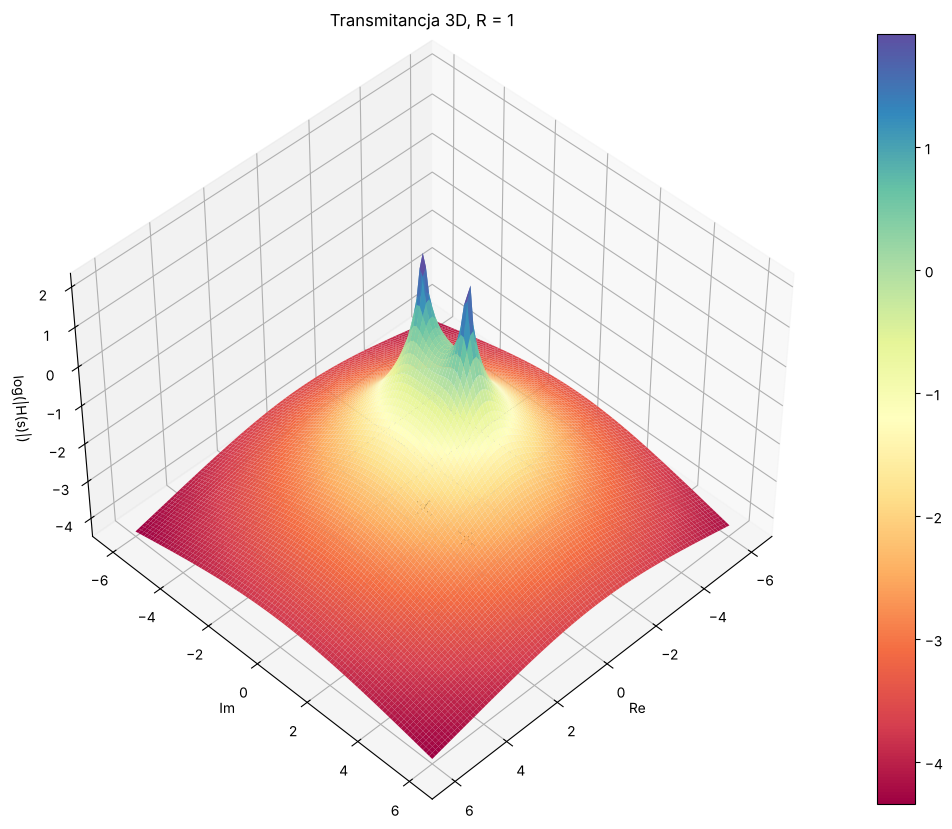

R = 0.3:  bieguny = [-0.15+0.989j -0.15-0.989j]


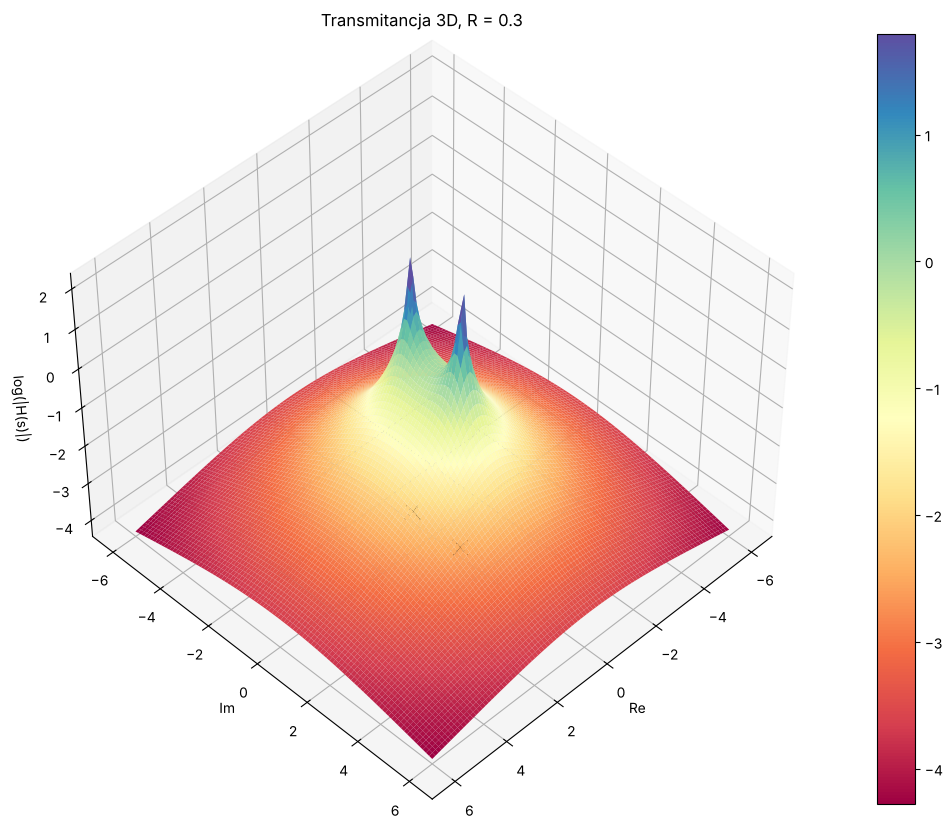

In [12]:
def transmitancja3D(R, L=1, C=1):
    B = np.poly1d([          1])                     # licznik: 1
    A = np.poly1d([C*L, C*R, 1])                     # mianownik: LC·s² + RC·s + 1
    print(f'R = {R}:  bieguny = {np.round(np.roots(A), 3)}')

    Re     = np.linspace(-6, 6, 100)                 # oś rzeczywista płaszczyzny s
    Im     = np.linspace(-6, 6, 100)                 # oś urojona płaszczyzny s
    RE, IM = np.meshgrid(Re, Im) #2D planes          # siatka 100×100 punktów
    s      = RE + IM*1j                              # macierz punktów zespolonych s = σ + jω
    H      = B(s)/A(s)                               # H(s) w każdym punkcie
    M      = np.abs(H)                               # |H(s)|

    ax = plt.figure(figsize=(18, 10)).add_subplot(projection='3d')   # okno z osiami 3D
    srf = ax.plot_surface(RE, IM, np.log(M), cmap='Spectral', cstride=1, rstride=1)   # powierzchnia log|H|
    p = np.roots(A)
    ax.plot(p.real, p.imag, np.log(M).min(), 'kx', markersize=12)   # bieguny na „podłodze”
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_zlabel("log(|H(s)|)")
    ax.set_title(f'Transmitancja 3D, R = {R}')
    ax.view_init(45, 45)                             # kąt patrzenia
    plt.colorbar(srf)                                # legenda kolorów
    plt.show()

transmitancja3D(1)          # R = 1   → ξ = 0.5
transmitancja3D(0.3)        # R = 0.3 → ξ = 0.15, bieguny blisko osi urojonej

**Wędrówka biegunów przy zmianie R** (komórka dodana – tzw. linie pierwiastkowe):

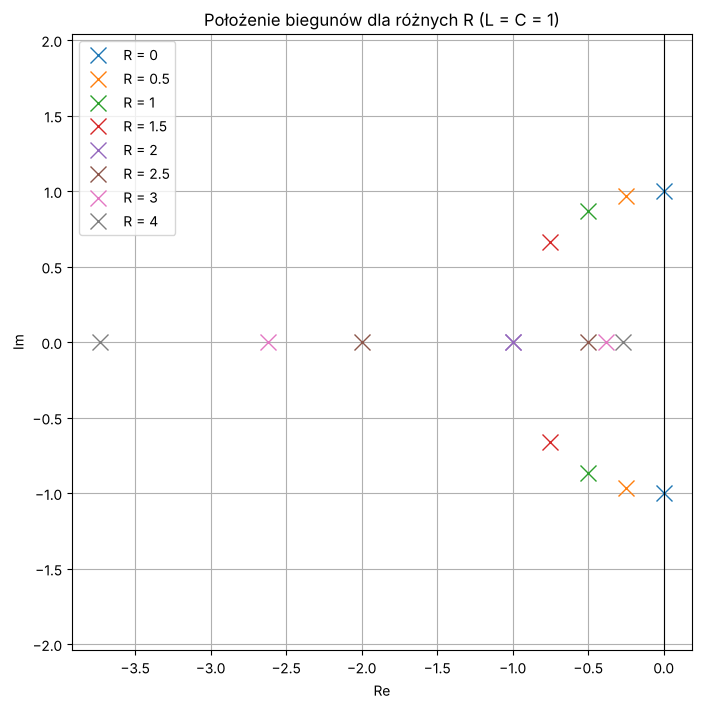

In [13]:
L, C = 1, 1
plt.figure(figsize=poles_figsize)
for R in [0, 0.5, 1, 1.5, 2, 2.5, 3, 4]:             # rosnące R
    p = np.roots([L*C, R*C, 1])                      # bieguny dla tego R
    plt.plot(p.real, p.imag, 'x', markersize=12, label=f'R = {R}')
plt.axvline(0, color='k', linewidth=0.8)             # oś urojona
plt.title('Położenie biegunów dla różnych R (L = C = 1)')
plt.xlabel('Re')
plt.ylabel('Im')
plt.axis('equal')
plt.legend()
plt.grid()
plt.show()

### ✅ Wnioski / odpowiedzi na pytania

- Kominy na wykresie 3D stoją **dokładnie w biegunach** (czarne krzyżyki).
- **Mniejsze R** → bieguny bliżej osi urojonej → kominy „wchodzą” na oś $j\omega$ → na charakterystyce amplitudowej pojawia się **wysoki, wąski rezonans**, a odpowiedź impulsowa drga długo.
- **Większe R** → bieguny odsuwają się w lewo → powierzchnia przy osi urojonej jest płaska → brak rezonansu, szybki zanik.
- Dla $R<2$ bieguny leżą na **okręgu** o promieniu $\omega_0=1$; przy $R=2$ spotykają się w $-1$; dla $R>2$ rozchodzą się po osi rzeczywistej.

---
# 🎓 Kolokwium – przykładowe pytania z rozwiązaniami
Pytania oznaczone **[z kolokwium]** to prawdziwe przykłady od prowadzącego, pozostałe są **wymyślone w tym samym stylu**. Przy każdym:
- **Odpowiedź (do wpisania)** – krótki tekst, który można wpisać w pole odpowiedzi,
- **Jak to rozwiązać** – kroki, żeby umieć zrobić podobne zadanie samemu,
- kod tam, gdzie zadanie wymaga obliczeń lub wykresu (na kolokwium można dołączyć zrzut wykresu jako obrazek).

### Pytanie 1 [z kolokwium]
**Wyznacz odpowiedź impulsową dla układu o transmitancji $\dfrac{1}{CLs^2+CRs+1}$, gdzie $R=-3$, $L=8$, $C=0{,}5$. Określ charakter odpowiedzi impulsowej oraz odpowiedz na pytanie: czy układ jest stabilny?**

**Jak to rozwiązać (modyfikacja zadania 4 z instrukcji):**
1. Mianownik: $A(s)=LC\,s^2+RC\,s+1=4s^2-1{,}5s+1$ → `A = [4, -1.5, 1]`, licznik `B = [1]`.
2. Bieguny: `np.roots(A)`.
3. Odpowiedź impulsowa: `calculateImpulseResponseFromNumDen(B, A, time)` i wykres.
4. Stabilność: czy wszystkie bieguny mają $\mathrm{Re}<0$?

**Odpowiedź (do wpisania):**
$A(s)=4s^2-1{,}5s+1$. Bieguny: $s_{1,2}=\frac{1{,}5\pm\sqrt{2{,}25-16}}{8}\approx0{,}1875\pm0{,}4635j$.
$\omega_0=\frac{1}{\sqrt{LC}}=0{,}5$, $\ \xi=\frac R2\sqrt{\frac CL}=-0{,}375<0$.
Bieguny są zespolone sprzężone i leżą w **prawej półpłaszczyźnie** ($\mathrm{Re}=0{,}1875>0$), więc odpowiedź impulsowa ma charakter **drgań sinusoidalnych o narastającej amplitudzie** (obwiednia $e^{0{,}1875t}$, pulsacja drgań $\approx0{,}46$ rad/s):
$$h(t)\approx0{,}54\,e^{0{,}1875t}\sin(0{,}4635\,t)$$
Odpowiedź impulsowa nie jest bezwzględnie sumowalna → **układ nie jest stabilny (BIBO)**. Przyczyną jest ujemna rezystancja, która dostarcza energię zamiast ją rozpraszać.

A(s) = [ 4.  -1.5  1. ]    bieguny = [0.1875+0.4635j 0.1875-0.4635j]
ω0 = 0.5    ξ = -0.375
stabilny? False


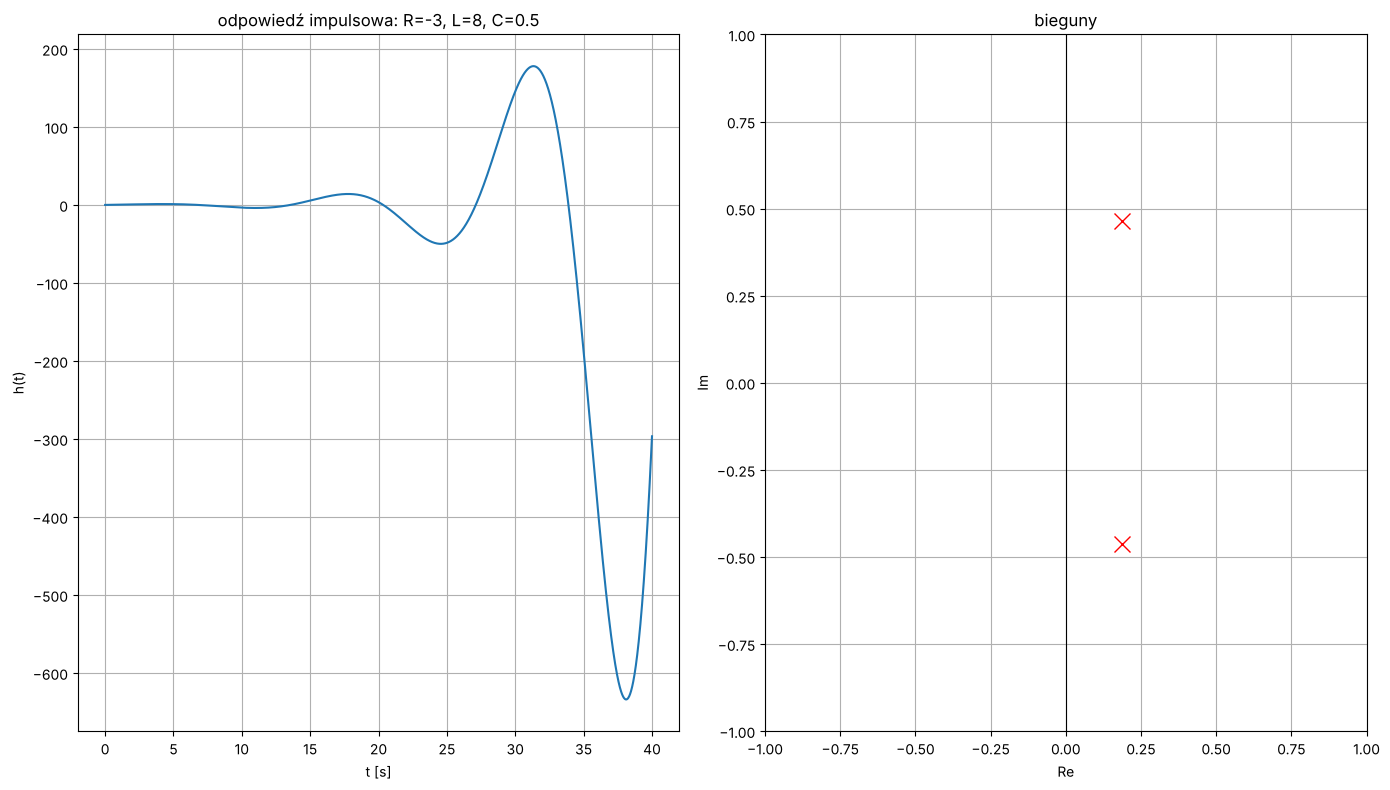

In [14]:
R, L, C = -3, 8, 0.5
B = np.poly1d([1])                             # licznik: 1
A = np.poly1d([L*C, R*C, 1])                   # mianownik: 4s² - 1.5s + 1
poles = np.roots(A)
print('A(s) =', A.coeffs, '   bieguny =', np.round(poles, 4))
print('ω0 =', 1/np.sqrt(L*C), '   ξ =', R/2*np.sqrt(C/L))
print('stabilny?', np.all(poles.real < 0))

time = np.linspace(0, 40, 4000)
impulse = calculateImpulseResponseFromNumDen(B, A, time)

plt.figure(figsize=default_figsize)
plt.subplot(1, 2, 1)
plt.plot(time, impulse)
plt.title('odpowiedź impulsowa: R=-3, L=8, C=0.5')
plt.xlabel('t [s]')
plt.ylabel('h(t)')
plt.grid()
plt.subplot(1, 2, 2)
plt.plot(poles.real, poles.imag, 'rx', markersize=12)
plt.axvline(0, color='k', linewidth=0.8)
plt.title('bieguny')
plt.xlabel('Re')
plt.ylabel('Im')
plt.xlim([-1, 1])
plt.ylim([-1, 1])
plt.grid()
plt.tight_layout()
plt.show()

### Pytanie 2
Dla $R=1$, $L=1$, $C=4$ wyznacz bieguny, współczynnik tłumienia $\xi$ i określ charakter odpowiedzi impulsowej.

**Odpowiedź (do wpisania):** $A(s)=4s^2+4s+1=(2s+1)^2$ → **podwójny** biegun $s=-0{,}5$. $\ \xi=\frac12\sqrt{\frac41}=1$ → przypadek **aperiodyczny krytyczny**: odpowiedź $h(t)\sim t\,e^{-0{,}5t}$ – rośnie, osiąga maksimum i wraca do zera bez drgań. Biegun ujemny → układ **stabilny**.

### Pytanie 3
Dla $R=0$, $L=2$, $C=0{,}5$ określ charakter odpowiedzi i stabilność.

**Odpowiedź (do wpisania):** $A(s)=s^2+1$ → bieguny $\pm j$ (na osi urojonej), $\xi=0$, $\omega_0=1$. Odpowiedź $h(t)=\sin t$ – **drgania niegasnące** (generator). $\int_0^\infty|\sin t|\,dt=\infty$ → układ **nie jest stabilny w sensie BIBO** (granica stabilności).

### Pytanie 4
Dla $R=6$, $L=1$, $C=1$ określ charakter odpowiedzi.

**Odpowiedź (do wpisania):** $A(s)=s^2+6s+1$, bieguny $-3\pm2\sqrt2\approx-0{,}17;\ -5{,}83$ – dwa różne rzeczywiste ujemne, $\xi=3>1$ → przypadek **przetłumiony**: odpowiedź bez drgań, powoli zanikająca (decyduje biegun $-0{,}17$ najbliżej zera). Układ **stabilny**.

R=1, L=1, C=4:  ξ = 1.00,  bieguny = [-0.5 -0.5],  stabilny: True
R=0, L=2, C=0.5:  ξ = 0.00,  bieguny = [-0.+1.j  0.-1.j],  stabilny: False
R=6, L=1, C=1:  ξ = 3.00,  bieguny = [-5.828 -0.172],  stabilny: True


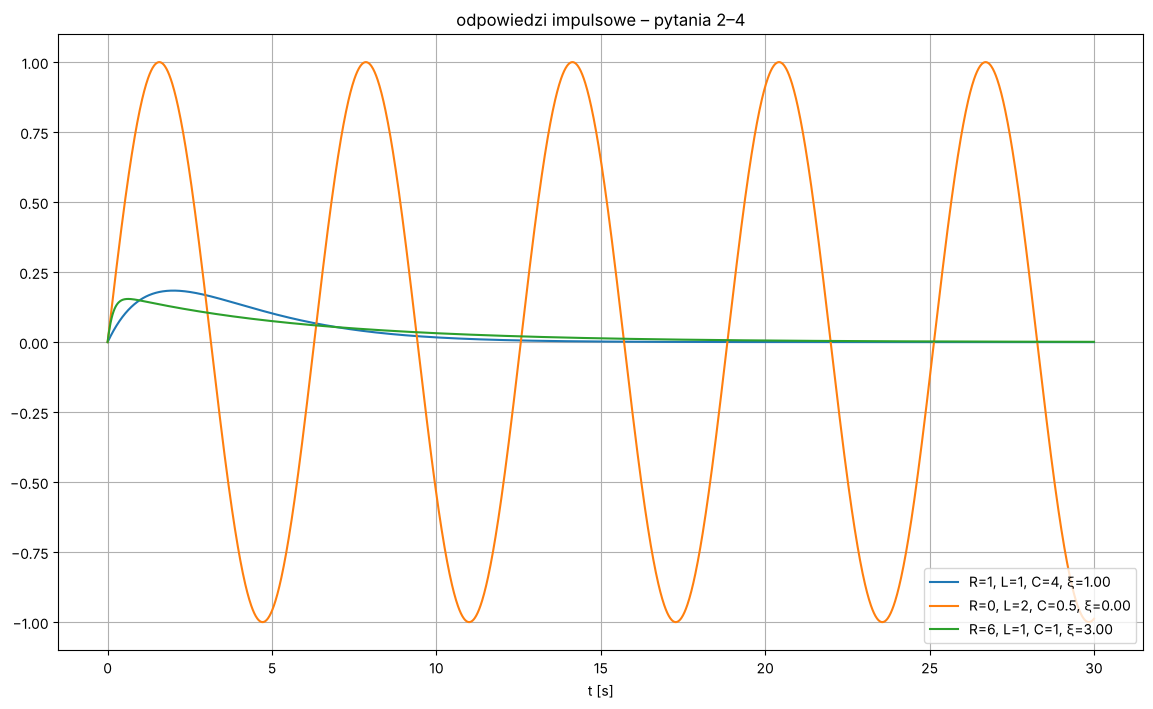

In [15]:
time = np.linspace(0, 30, 2000)
plt.figure(figsize=default_figsize)
for R, L, C in [(1, 1, 4), (0, 2, 0.5), (6, 1, 1)]:
    A = np.poly1d([L*C, R*C, 1])
    p = np.roots(A)
    xi = R/2*np.sqrt(C/L)
    print(f'R={R}, L={L}, C={C}:  ξ = {xi:.2f},  bieguny = {np.round(p, 3)},  stabilny: {np.all(p.real < 0)}')
    plt.plot(time, calculateImpulseResponseFromNumDen([1], A, time), label=f'R={R}, L={L}, C={C}, ξ={xi:.2f}')
plt.title('odpowiedzi impulsowe – pytania 2–4')
plt.xlabel('t [s]')
plt.legend()
plt.grid()
plt.show()

### Pytanie 5 (teoria)
Kiedy układ LTI jest stabilny w sensie BIBO? Jak to sprawdzić na podstawie transmitancji?

**Odpowiedź (do wpisania):** układ jest stabilny BIBO, gdy każde ograniczone wejście daje ograniczone wyjście, co jest równoważne bezwzględnej sumowalności odpowiedzi impulsowej $\int_0^\infty|h(t)|\,dt<\infty$. Na podstawie transmitancji: **wszystkie bieguny** (pierwiastki mianownika $A(s)$) muszą leżeć w **lewej półpłaszczyźnie** zespolonej, $\mathrm{Re}\,p_i<0$. Biegun na osi urojonej lub w prawej półpłaszczyźnie oznacza brak stabilności.

### Pytanie 6 (teoria)
Jak zmiana pojemności $C$ wpływa na częstotliwość drgań układu RLC?

**Odpowiedź (do wpisania):** $\omega_0=\frac{1}{\sqrt{LC}}$ – zwiększenie $C$ **zmniejsza** pulsację drgań własnych (drgania wolniejsze, dłuższy okres), zmniejszenie $C$ ją zwiększa. Zmiana $C$ wpływa też na tłumienie: $\xi=\frac R2\sqrt{\frac CL}$.

---
## 📝 Ściąga – Laboratorium 5

**Wzory**
$$Z_R=R,\quad Z_L=sL,\quad Z_C=\frac{1}{sC},\qquad H_{RC}=\frac{1}{RCs+1},\qquad H_{RLC}=\frac{1}{LCs^2+RCs+1}$$
$$H(s)=\frac{\omega_0^2}{s^2+2\xi\omega_0s+\omega_0^2},\qquad \omega_0=\frac{1}{\sqrt{LC}},\qquad \xi=\frac R2\sqrt{\frac CL}$$

| $\xi$ | bieguny | odpowiedź |
|---|---|---|
| $0$ | $\pm j\omega_0$ | drgania niegasnące – **niestabilny BIBO** |
| $(0,1)$ | zespolone, Re < 0 | drgania gasnące |
| $1$ | podwójny $-\omega_0$ | krytyczny |
| $>1$ | dwa rzeczywiste < 0 | przetłumiony |
| $<0$ (R < 0) | Re > 0 | narastanie – **niestabilny** |

**Stabilny BIBO ⇔ wszystkie bieguny Re < 0 ⇔ $\int_0^\infty|h|\,dt<\infty$.**

**Kod**
| | |
|---|---|
| `np.poly1d([L*C, R*C, 1])` | mianownik |
| `np.roots(A)` | bieguny |
| `plt.plot(p.real, p.imag, 'rx')` | rysowanie biegunów |
| `scipy.signal.impulse(scipy.signal.tf2ss(B, A), T=t)[1]` | odpowiedź impulsowa |
| `sympy.cancel(H)` | postać wielomian/wielomian |
| `np.meshgrid(x, y)` | siatka do wykresu 3D |
| `plt.figure().add_subplot(projection='3d')` | osie 3D |